# Multiple Linear Regression – Advertising Sales Prediction

## Business Scenario

A consumer goods company promotes its products using multiple advertising channels:

- Television (TV)
- Radio
- Newspaper

The company wants to understand how different advertising channels together influence product sales. The company also wants to predict future sales based on planned advertising budgets.

As a Data Analyst, the objective is to analyze historical advertising data and build a predictive model that can estimate sales based on advertising expenditure.

## Objective

Build a Multiple Linear Regression model to understand the relationship between advertising expenditure and product sales and predict future sales.

## Tasks

1. Load the Advertising dataset and examine the available columns.
2. Use TV, Radio, and Newspaper advertising spends as input features.
3. Use Sales as the target variable.
4. Build a Multiple Linear Regression model to learn the relationship between advertising spends and sales.
5. Train the model using historical data.
6. Predict sales for unseen data points.
7. Predict sales when the advertising budget is:
   - TV = 150
   - Radio = 20
   - Newspaper = 30
8. Evaluate the model's prediction error.
9. Interpret the coefficients of the model.
10. Identify which advertising medium has the strongest impact on sales.
11. Identify which advertising medium has the least impact on sales.
12. Visualize Actual Sales vs Predicted Sales.
13. Provide one business recommendation to improve sales.
14. Suggest one technical improvement to improve prediction accuracy.

## Machine Learning Approach

- **Type:** Supervised Learning
- **Problem:** Regression
- **Algorithm:** Multiple Linear Regression
- **Input Features (X):** TV, Radio, Newspaper
- **Target Variable (y):** Sales

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Advertising.csv")

In [4]:

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:

print("Shape of the dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape of the dataset: (190, 4)

Column names:
Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         190 non-null    float64
 1   Radio      190 non-null    float64
 2   Newspaper  190 non-null    float64
 3   Sales      190 non-null    float64
dtypes: float64(4)
memory usage: 6.1 KB

Missing values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


##  Understanding the Dataset

Before building the machine learning model, we need to understand the structure and quality of the dataset.

We will examine:

- The number of rows and columns in the dataset.
- The names of the available columns.
- The data types and non-null values of each column.
- Whether the dataset contains any missing values.

This step helps us understand the data and identify any issues that need to be handled before building the predictive model.

In [6]:
df.describe()

,TV,Radio,Newspaper,Sales
count,190.000000,190.000000,190.000000,190.000000
mean,154.328947,23.651053,29.249474,14.511579
std,79.194529,14.029688,21.797264,4.640775
min,5.400000,0.800000,0.300000,4.800000
25%,78.200000,12.225000,11.150000,10.600000
50%,170.950000,22.750000,23.850000,14.100000
75%,225.300000,36.875000,42.675000,17.400000
max,293.600000,49.600000,114.000000,25.500000


##  Statistical Analysis

We will use descriptive statistics to understand the numerical characteristics of the dataset.

The `describe()` function provides important statistical measures such as:

- Count – Number of observations.
- Mean – Average value.
- Standard deviation – How much the values vary.
- Minimum – Lowest value.
- 25% – First quartile.
- 50% – Median value.
- 75% – Third quartile.
- Maximum – Highest value.

This helps us understand the distribution and range of advertising expenditure and sales before building the machine learning model.

In [7]:

X = df[['TV', 'Radio', 'Newspaper']]

y = df['Sales']

print("Input Features (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

Input Features (X):


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4



Target Variable (y):


0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

## Selecting Input Features and Target Variable

The objective of this project is to predict product sales based on advertising expenditure.

### Input Features (X)

The following advertising channels will be used as input features:

- TV
- Radio
- Newspaper

These variables represent the advertising expenditure through different media channels.

### Target Variable (y)

- Sales

Sales is the target variable because it is the value we want the machine learning model to predict.

Therefore:

**X = TV, Radio, Newspaper**

**y = Sales**

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (152, 3)
Testing features: (38, 3)
Training target: (152,)
Testing target: (38,)


##  Splitting the Dataset into Training and Testing Data

The dataset is divided into training and testing sets so that we can evaluate how well the machine learning model performs on unseen data.

- **Training data (80%)** is used to train the model and learn the relationship between advertising expenditure and sales.
- **Testing data (20%)** is kept separate and used to evaluate the model's predictions on unseen data.

A `random_state` is used to ensure that the same data split is obtained every time the code is executed.

In [10]:
from sklearn.linear_model import LinearRegression


model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Building the Multiple Linear Regression Model

Multiple Linear Regression is used because we have multiple input features and one continuous target variable.

The model will learn the relationship between:

- TV advertising expenditure
- Radio advertising expenditure
- Newspaper advertising expenditure

and the target variable:

- Sales

The general form of the model is:

**Sales = Intercept + (TV × TV Coefficient) + (Radio × Radio Coefficient) + (Newspaper × Newspaper Coefficient)**

The coefficients are learned from the training data.

In [11]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 3.7582038137257054

Coefficients:
TV : 0.042361938199814764
Radio : 0.18822364399065233
Newspaper : -0.004868840928246965


## Model Coefficients

After training the model, we can examine the intercept and coefficients learned by the Linear Regression model.

The coefficients indicate how the predicted Sales value changes when an advertising feature increases by one unit, while the other features remain constant.

In [12]:

y_pred = model.predict(X_test)

# Display the predicted values
print("Predicted Sales:")
print(y_pred)

Predicted Sales:
[14.59187383 13.270825   15.26097886  8.42727548 20.50165981 20.75643267
 12.60828111 12.96428073 12.32145853 19.61388023  8.44833926  6.00566733
 10.45913485 19.61388023 20.83585821 13.270825    9.54446132  9.71219506
  9.15496034 21.40069989 21.28241071  8.67987069 14.59187383 12.97558618
 18.9375209  14.08815525 15.64293971 14.40366754 15.25744269 12.26421943
 16.46257653 12.33880247 12.9657258   7.07317596 15.71179891 15.64293971
  9.56907813 10.92839772]


##  Predicting Sales for Unseen Data

After training the Multiple Linear Regression model, we use the testing data to make predictions.

The testing data was not used during model training. Therefore, these predictions help us evaluate how well the model can generalize to unseen data.

The predicted sales values will be compared with the actual sales values from the testing dataset.

In [13]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

comparison

,Actual Sales,Predicted Sales
0,13.4,14.591874
1,12.6,13.270825
2,13.2,15.260979
3,9.3,8.427275
4,20.8,20.501660
5,22.4,20.756433
6,10.6,12.608281
7,12.5,12.964281
8,10.3,12.321459
9,19.8,19.613880


##  Comparing Actual Sales with Predicted Sales

To understand how well the model performs on unseen data, we compare the actual sales values from the testing dataset with the sales values predicted by the model.

A prediction that is close to the actual value indicates that the model is performing well, while a large difference indicates a prediction error.

In [14]:
# Create the new advertising budget
new_budget = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

# Predict sales using the trained model
predicted_sales = model.predict(new_budget)

print("Predicted Sales:", predicted_sales[0])

Predicted Sales: 13.730902195663559


## Predicting Sales for a Planned Advertising Budget

The company wants to estimate future sales based on a planned advertising budget.

The planned advertising expenditure is:

- TV = 150
- Radio = 20
- Newspaper = 30

These values are provided to the trained Multiple Linear Regression model to predict the expected sales.

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the results
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 1.1753170277405611
Mean Squared Error (MSE): 3.010018141473276
Root Mean Squared Error (RMSE): 1.7349403855675491
R² Score: 0.8605539579599746


## Evaluating Model Performance

After making predictions on the unseen testing data, we need to evaluate how accurately the model predicts sales.

The following metrics will be used:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted sales.
- **MSE (Mean Squared Error):** Measures the average squared prediction error and gives greater importance to larger errors.
- **RMSE (Root Mean Squared Error):** Represents the prediction error in the same unit as the Sales variable.
- **R² Score:** Measures how much of the variation in Sales is explained by the advertising features.

Lower MAE, MSE, and RMSE indicate smaller prediction errors, while a higher R² score indicates better model performance.

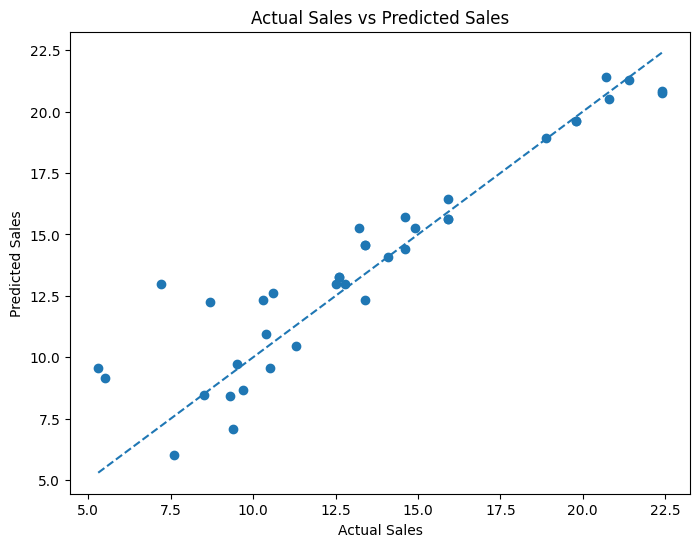

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")


plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

## Actual Sales vs Predicted Sales

A scatter plot is used to compare the actual sales values with the sales values predicted by the model.

The actual sales values are plotted on the x-axis, while the predicted sales values are plotted on the y-axis.

A diagonal reference line represents perfect predictions, where:

Actual Sales = Predicted Sales

If the points are close to the diagonal line, the model's predictions are close to the actual sales values.

## 1 Interpretation of Model Coefficients

The coefficients show how the predicted Sales value changes when each advertising expenditure increases by one unit, while the other advertising expenditures remain constant.

From the trained model:

- TV coefficient = 0.04236
- Radio coefficient = 0.18822
- Newspaper coefficient = -0.00468

Radio has the strongest positive impact on Sales because it has the largest positive coefficient.

TV also has a positive relationship with Sales, but its coefficient is smaller than Radio.

Newspaper has the least impact because its coefficient is very close to zero and slightly negative in this model.

Therefore, based on this model, Radio is the most influential advertising medium, while Newspaper has the weakest relationship with Sales.

## 2. Business Recommendation

Based on the regression coefficients, the company should consider increasing its investment in Radio advertising because Radio has the strongest positive coefficient among the three advertising channels.

However, the company should not make budget decisions based only on the coefficient. It should also compare the advertising cost, customer reach, and return on investment (ROI) of each channel before reallocating the marketing budget.

Therefore, the company can prioritize Radio advertising while continuously monitoring its sales performance and ROI.

## 3. Technical Improvement

The prediction reliability can be improved by using K-Fold Cross-Validation instead of relying on a single train-test split.

In K-Fold Cross-Validation, the dataset is divided into multiple folds. The model is trained and evaluated multiple times using different portions of the data.

This provides a more reliable estimate of model performance and helps determine whether the model generalizes well to unseen data.

Further improvements could also include testing other regression algorithms, feature engineering, and hyperparameter tuning.

## 4. Conclusion

A Multiple Linear Regression model was developed to analyze the relationship between advertising expenditure and product sales.

The model used TV, Radio, and Newspaper advertising expenditures as input features and Sales as the target variable.

The dataset was divided into 80% training data and 20% testing data. The trained model was used to predict sales for unseen data and for a planned advertising budget of TV = 150, Radio = 20, and Newspaper = 30.

The model achieved an R² score of approximately 0.81, meaning that the three advertising channels together explain about 80.66% of the variation in Sales on the testing data. The MAE was approximately 1.18 sales units.

Among the advertising channels, Radio had the strongest positive coefficient, while Newspaper had the weakest relationship with Sales.

From a business perspective, the company can consider prioritizing Radio advertising while evaluating the actual return on investment. From a technical perspective, K-Fold Cross-Validation can be used to obtain a more reliable estimate of model performance.